# Eight wells in 2D: Prinz × double well
[Open in Colab](https://colab.research.google.com/github/paulrobustelli/CSMP_150_2026/blob/main/notebooks/Prinz_2D_Eight_Well_MSM.ipynb)

**A compact teaching example:** four wells in x, two in y, and an eight-state MSM. This is our explicitly defined 2D extension, not a canonical published 2D Prinz potential.

$$V(x,y)=V_P(x)+V_D(y),$$
$$V_P(x)=2x^8+0.8e^{-80x^2}+0.2e^{-80(x-0.5)^2}+0.5e^{-40(x+0.5)^2},\qquad V_D(y)=0.6\left[(y/0.55)^2-1\right]^2.$$

We use reversible local Metropolis dynamics on a fixed 40×40 grid, with $\beta=5$. Time is measured in **MC steps**, not ns. The fine-grid chain generates trajectories; its 1,600 positions are grouped into **eight basin states** for the MSM.

**Story:** look at the landscape → sample it → estimate an 8×8 matrix → identify its modes → put all population in one basin → watch it relax. The code is complete and can be used as an instructor demonstration; short exercises at the end invite students to repeat the estimation and change the model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.sparse.csgraph import connected_components
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.colors import PowerNorm, SymLogNorm
from IPython.display import display, Video
from pathlib import Path
np.set_printoptions(precision=4,suppress=True)
OUTPUT=Path(".")
N=40;beta=5.;q=.25
x=np.linspace(-1,1,N);y=x.copy();X,Y=np.meshgrid(x,y)
def prinz(x):
    return 2*x**8+.8*np.exp(-80*x*x)+.2*np.exp(-80*(x-.5)**2)+.5*np.exp(-40*(x+.5)**2)
def double_well(y):return .6*((y/.55)**2-1)**2
energy=prinz(X)+double_well(Y)
def chain_1d(energy):
    P=np.zeros((N,N))
    for i in range(N):
        for j in [i-1,i+1]:
            if 0<=j<N:P[i,j]=q*min(1.,np.exp(-beta*(energy[j]-energy[i])))
        P[i,i]=1-P[i].sum()
    w=np.exp(-beta*(energy-energy.min()));w/=w.sum()
    np.testing.assert_allclose(w[:,None]*P,w[None,:]*P.T,atol=1e-14)
    return P,w
Px,wx=chain_1d(prinz(x));Py,wy=chain_1d(double_well(y))
W=np.outer(wy,wx);w=W.ravel()
# State order: lower row A−, B−, C−, D−; upper row A+, B+, C+, D+.
labels=["A−","B−","C−","D−","A+","B+","C+","D+"]
xb=np.digitize(x,[-.5,0,.5]);yb=(y>=0).astype(int)
assignment=(4*yb[:,None]+xb[None,:]).ravel()
H=np.eye(8)[assignment];pi_exact=w@H
centers_x=np.array([-.75,-.25,.25,.75]);centers_y=np.array([-.5,.5])


## 1. Eight wells and their equilibrium populations
$$\mu(x,y)\propto e^{-\beta V(x,y)},\qquad \pi_s=\sum_{z\in s}w_z.$$
$w_z$ is the equilibrium probability of a fine-grid position; $\pi_s$ is the total probability of a basin. The y potential is symmetric, so corresponding upper and lower basins have equal equilibrium populations.

White lines mark the MSM boundaries, at x = −0.5, 0, 0.5 and y = 0. Color bars distinguish energy, probability per fine-grid cell, and probability per basin.

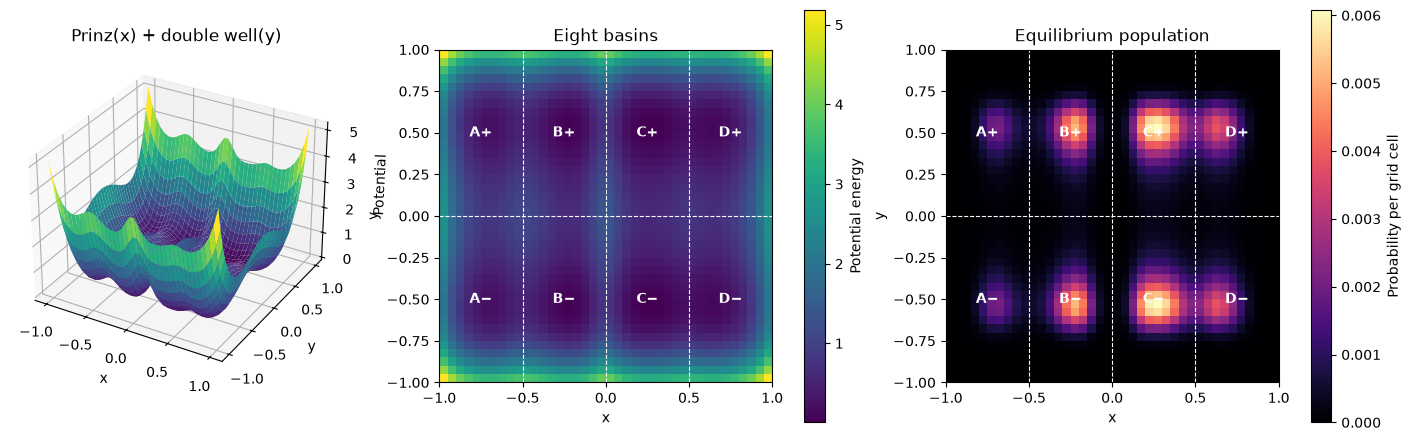

Basin order: ['A−', 'B−', 'C−', 'D−', 'A+', 'B+', 'C+', 'D+']
Equilibrium basin probabilities: [0.0527 0.1335 0.2097 0.1041 0.0527 0.1335 0.2097 0.1041]


In [2]:
def basin_grid(ax,annotate=True):
    for edge in [-.5,0,.5]:ax.axvline(edge,color="white",lw=.8,ls="--")
    ax.axhline(0,color="white",lw=.8,ls="--")
    if annotate:
        for s in range(8):ax.text(centers_x[s%4],centers_y[s//4],labels[s],ha="center",va="center",color="white",weight="bold")
fig=plt.figure(figsize=(14,4.3),layout="constrained")
a=fig.add_subplot(131,projection="3d");a.plot_surface(X,Y,energy,cmap="viridis",linewidth=0)
a.set(xlabel="x",ylabel="y",zlabel="Potential",title="Prinz(x) + double well(y)")
b=fig.add_subplot(132);im=b.imshow(energy,origin="lower",extent=(-1,1,-1,1),cmap="viridis")
basin_grid(b);b.set(title="Eight basins",xlabel="x",ylabel="y");fig.colorbar(im,ax=b,label="Potential energy")
a=fig.add_subplot(133);im=a.imshow(W,origin="lower",extent=(-1,1,-1,1),cmap="magma")
basin_grid(a);a.set(title="Equilibrium population",xlabel="x",ylabel="y");fig.colorbar(im,ax=a,label="Probability per grid cell")
fig.savefig(OUTPUT/"Prinz_8well_landscape.png",dpi=180);plt.show()
print("Basin order:",labels)
print("Equilibrium basin probabilities:",pi_exact)
np.testing.assert_allclose(pi_exact[:4],pi_exact[4:],atol=1e-14)


## 2. Run local MC trajectories
At every step, choose x or y with probability 1/2 and apply one step of that coordinate's Metropolis chain. Rejected moves count as steps. The particle's 3D height is always the potential evaluated at its current position.

Training and validation use independent seeds. Training starts at equilibrium; this supports the simple reversible count estimator used below. The later nonequilibrium experiment starts from one basin and is a separate propagation task.

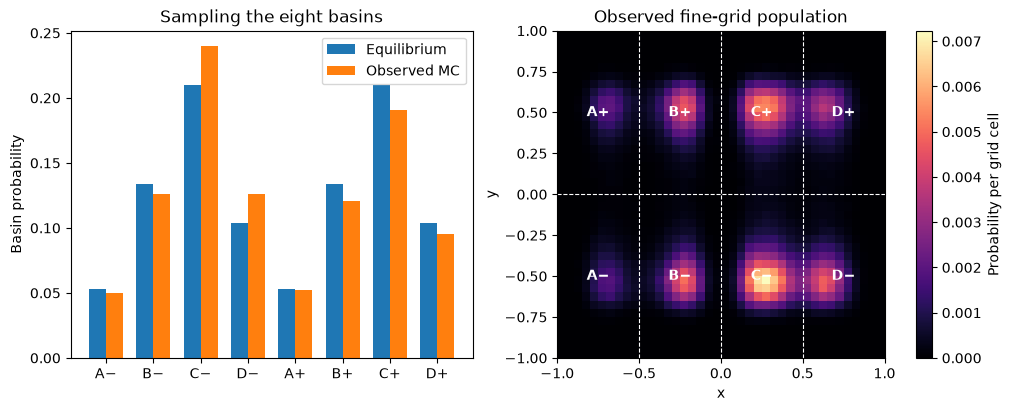

Training steps: 2000000 Validation steps: 1000000


In [3]:
def simulate(steps,seed,start=None):
    rng=np.random.default_rng(seed)
    state=int(rng.choice(N*N,p=w)) if start is None else int(start)
    iy,ix=divmod(state,N)
    path=np.empty(steps+1,dtype=np.int16);path[0]=state
    axes=rng.integers(0,2,size=steps);draws=rng.random(steps)
    lx=np.r_[0,np.diag(Px,-1)];rx=np.r_[np.diag(Px,1),0]
    ly=np.r_[0,np.diag(Py,-1)];ry=np.r_[np.diag(Py,1),0]
    for t in range(steps):
        r=draws[t]
        if axes[t]==0:ix+=(-1 if r<lx[ix] else (1 if r<lx[ix]+rx[ix] else 0))
        else:iy+=(-1 if r<ly[iy] else (1 if r<ly[iy]+ry[iy] else 0))
        path[t+1]=iy*N+ix
    return path
STEPS_PER_PATH=250_000
training=[simulate(STEPS_PER_PATH,s) for s in range(7100,7108)]
validation=[simulate(STEPS_PER_PATH,s) for s in range(7200,7204)]
for path in training+validation:
    iy,ix=np.divmod(path.astype(int),N)
    assert np.all(np.abs(np.diff(ix))+np.abs(np.diff(iy))<=1)
observed=np.bincount(np.concatenate(training),minlength=N*N).astype(float);observed/=observed.sum()
fig,axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
xx=np.arange(8)
axes[0].bar(xx-.18,pi_exact,width=.36,label="Equilibrium")
axes[0].bar(xx+.18,observed@H,width=.36,label="Observed MC")
axes[0].set(xticks=xx,xticklabels=labels,ylabel="Basin probability",title="Sampling the eight basins");axes[0].legend()
im=axes[1].imshow(observed.reshape(N,N),origin="lower",extent=(-1,1,-1,1),cmap="magma")
basin_grid(axes[1]);axes[1].set(title="Observed fine-grid population",xlabel="x",ylabel="y")
fig.colorbar(im,ax=axes[1],label="Probability per grid cell")
fig.savefig(OUTPUT/"Prinz_8well_populations.png",dpi=180);plt.show()
print("Training steps:",len(training)*STEPS_PER_PATH,"Validation steps:",len(validation)*STEPS_PER_PATH)


## 3. Estimate the 8×8 MSM from counts
For lag $\tau$, $C_{ij}(\tau)$ counts transitions from basin i to basin j within each trajectory. Never count across trajectory boundaries.
$$F=(C+C^T)/2,\qquad T_{ij}=F_{ij}/\sum_jF_{ij},\qquad\widehat\pi_i=\sum_jF_{ij}/\sum_{ij}F_{ij}.$$
This is a reversible **symmetrized-count estimator**, not reversible maximum likelihood. The fitted equilibrium $\widehat\pi$ comes from counts; the known fine-grid equilibrium is a reference, not input to this fit.

The main demonstration uses lag 200 MC steps. Eight basins need not be Markovian at every lag; the checks below assess this approximation.

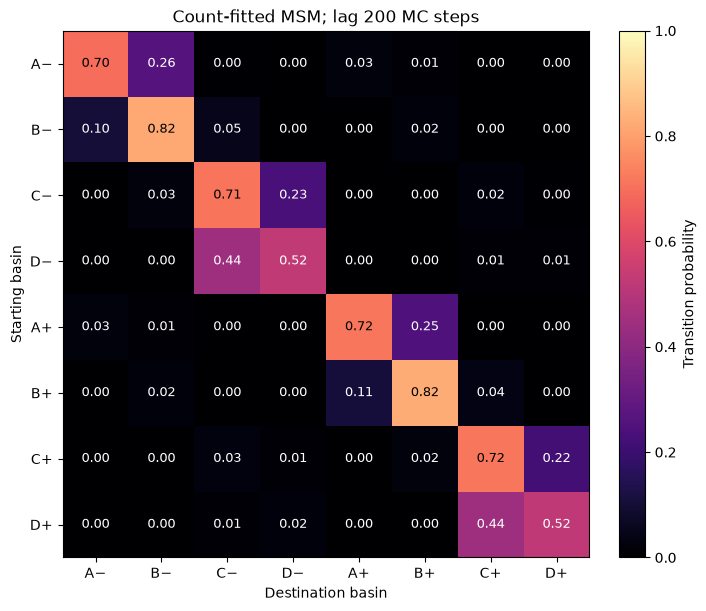

Outgoing counts: [ 99395 252038 478809 251439 104850 241215 380578 190084]


In [4]:
def counts_at(paths,lag):
    C=np.zeros((8,8),dtype=np.int64)
    for path in paths:
        s=assignment[path]
        C+=np.bincount(s[:-lag]*8+s[lag:],minlength=64).reshape(8,8)
    return C
def fit(C):
    F=(C+C.T)/2;totals=F.sum(1)
    if np.any(totals==0) or connected_components(F>0,directed=False,return_labels=False)!=1:
        raise ValueError("Insufficient connected sampling: extend the simulation")
    return F/totals[:,None],totals/totals.sum()
LAG=200
C=counts_at(training,LAG);T,pi=fit(C)
np.testing.assert_allclose(T.sum(1),1,atol=1e-12)
np.testing.assert_allclose(pi@T,pi,atol=1e-12)
np.testing.assert_allclose(pi[:,None]*T,pi[None,:]*T.T,atol=1e-12)
fig,ax=plt.subplots(figsize=(7,6),layout="constrained")
im=ax.imshow(T,cmap="magma",vmin=0,vmax=1)
for i in range(8):
    for j in range(8):ax.text(j,i,f"{T[i,j]:.2f}",ha="center",va="center",fontsize=9,color="black" if T[i,j]>.6 else "white")
ax.set(xticks=range(8),yticks=range(8),xticklabels=labels,yticklabels=labels,xlabel="Destination basin",ylabel="Starting basin",title=f"Count-fitted MSM; lag {LAG} MC steps")
fig.colorbar(im,ax=ax,label="Transition probability")
fig.savefig(OUTPUT/"Prinz_8well_transition_matrix.png",dpi=180);plt.show()
print("Outgoing counts:",C.sum(1))


## 4. What are the dominant exchange patterns?
$$T\psi_i=\lambda_i\psi_i,\qquad\sum_s\widehat\pi_s\psi_i(s)\psi_j(s)=\delta_{ij}.$$
Each eigenvector has eight entries—one per basin. Plot them at their spatial locations. The first mode is constant. The other modes describe signed patterns of population imbalance. Their signs are arbitrary until combined with the initial amplitudes.

Below, diagonalize $D_{\widehat\pi}^{1/2}TD_{\widehat\pi}^{-1/2}$ to obtain real eigenvalues and equilibrium-normalized eigenvectors. The reported modes are properties of the **fitted eight-state model**.

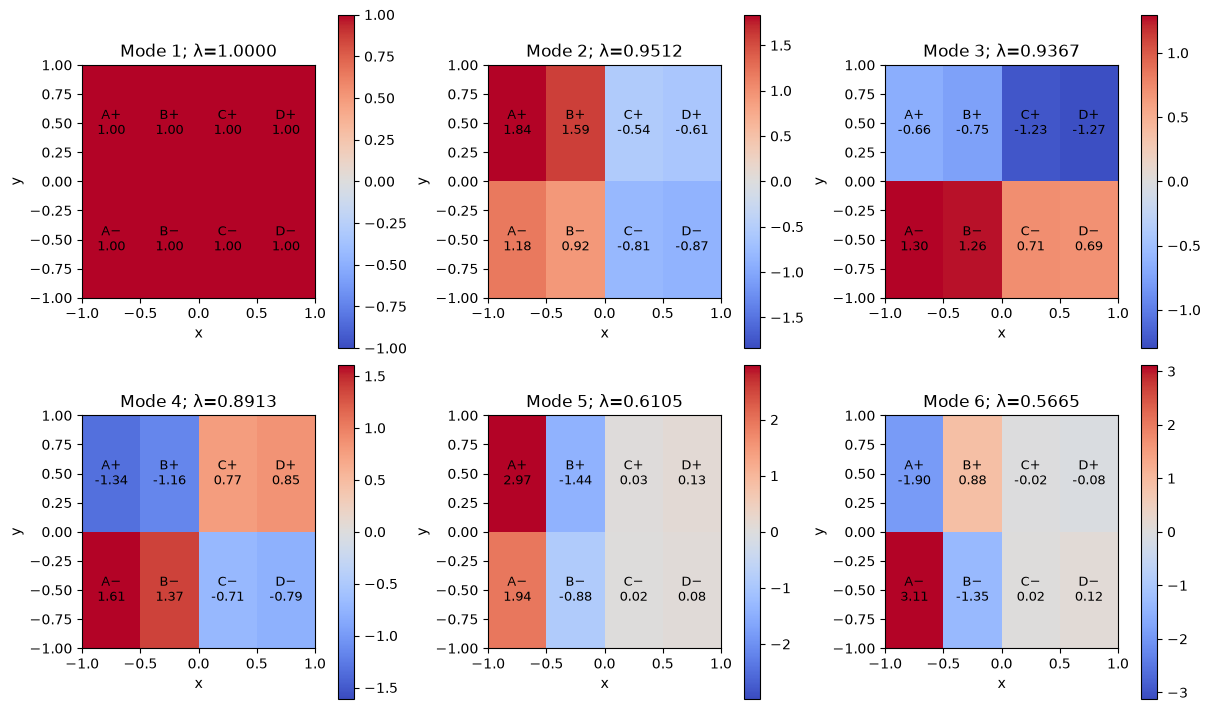

Eigenvalues: [1.     0.9512 0.9367 0.8913 0.6105 0.5665 0.299  0.2755]
Timescales at this lag: [np.float64(3996.4681786857163), np.float64(3056.818119891452), np.float64(1738.2694785951535), np.float64(405.22898449706133), np.float64(351.9539151477911), np.float64(165.6464936859292), np.float64(155.1605871043636)]


In [5]:
def eigensystem(T,pi):
    root=np.sqrt(pi);S=root[:,None]*T/root[None,:]
    np.testing.assert_allclose(S,S.T,atol=1e-12)
    vals,U=eigh(S);vals=vals[::-1];psi=U[:,::-1]/root[:,None]
    for i in range(8):
        if psi[np.argmax(abs(psi[:,i])),i]<0:psi[:,i]*=-1
    return vals,psi
vals,psi=eigensystem(T,pi)
np.testing.assert_allclose(T@psi,psi*vals,atol=1e-11)
np.testing.assert_allclose(psi.T@(pi[:,None]*psi),np.eye(8),atol=1e-11)
np.testing.assert_allclose(psi[:,0],1,atol=1e-10)
fig,axes=plt.subplots(2,3,figsize=(12,7),layout="constrained")
for i,ax in enumerate(axes.ravel()):
    field=psi[:,i].reshape(2,4);limit=max(abs(psi[:,i]))
    im=ax.imshow(field,origin="lower",extent=(-1,1,-1,1),aspect="equal",cmap="coolwarm",vmin=-limit,vmax=limit)
    for s in range(8):ax.text(centers_x[s%4],centers_y[s//4],f"{labels[s]}\n{psi[s,i]:.2f}",ha="center",va="center",fontsize=9)
    ax.set(title=f"Mode {i+1}; λ={vals[i]:.4f}",xlabel="x",ylabel="y");fig.colorbar(im,ax=ax)
fig.savefig(OUTPUT/"Prinz_8well_eigenmodes.png",dpi=180);plt.show()
print("Eigenvalues:",vals)
print("Timescales at this lag:",[-LAG/np.log(v) if 0<v<1 else np.nan for v in vals[1:]])


## 5. Refit at different lags; check predictions
$$t_i(\tau)=-\tau/\log\lambda_i(\tau),\qquad T(k\tau)\stackrel{?}{\approx}T(\tau)^k.$$
Refit from counts at each lag for the timescale plot. For the CK plot, compare powers of the lag-200 matrix with direct counts from held-out trajectories. Points are estimates, not exact truths. This compact lesson shows all eight return probabilities; the exercise extends the check to all 64 entries.

For a sampling-free comparison, exploit separability: the fine-grid random-axis chain has eigenvalues $(\lambda_a^x+\lambda_b^y)/2$ and product eigenvectors. This lets us calculate the exact basin-projected reference without fitting it to data.

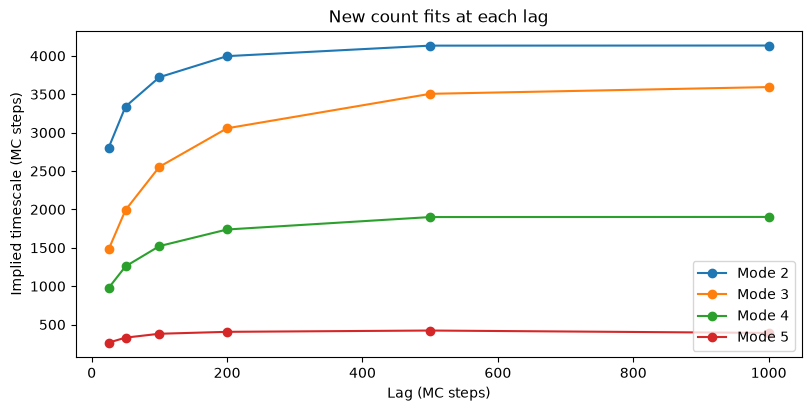

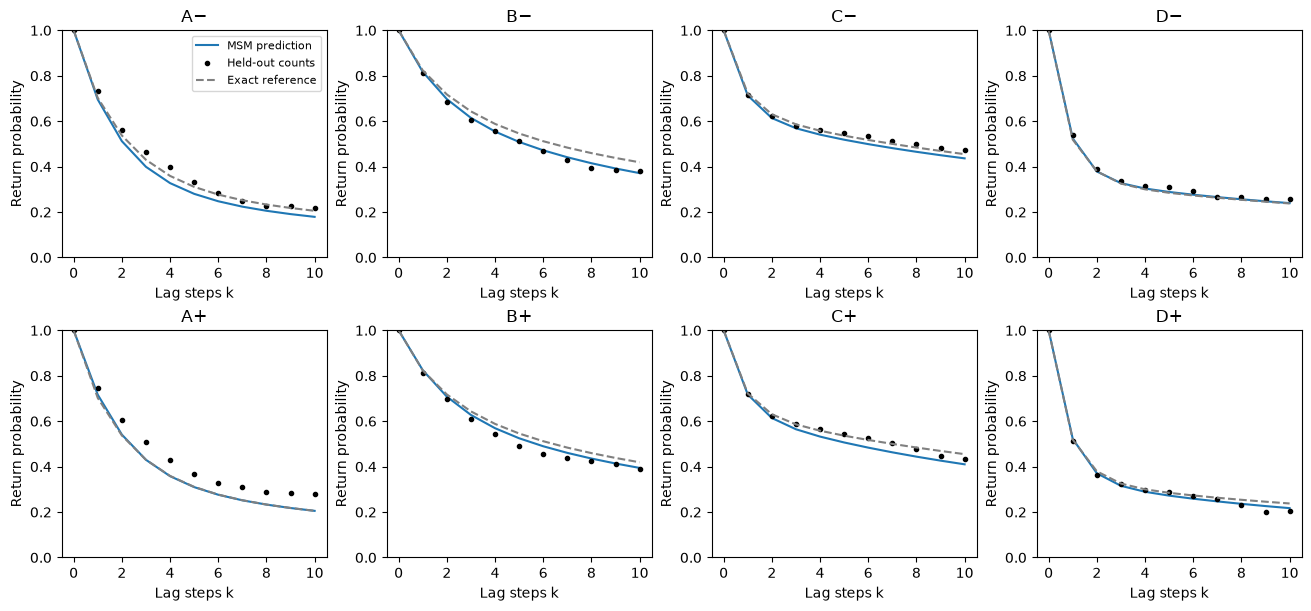

Max all-entry error vs exact, k=1..10: 0.05085048712073498


In [6]:
lags=np.array([25,50,100,200,500,1000]);its=[]
for lag in lags:
    fitted,mass=fit(counts_at(training,int(lag)));v,_=eigensystem(fitted,mass)
    its.append([-lag/np.log(z) if 0<z<1 else np.nan for z in v[1:5]])
fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
for i in range(4):ax.plot(lags,np.array(its)[:,i],"o-",label=f"Mode {i+2}")
ax.set(xlabel="Lag (MC steps)",ylabel="Implied timescale (MC steps)",title="New count fits at each lag");ax.legend();plt.show()
ex,Ux=eigh(np.sqrt(wx)[:,None]*Px/np.sqrt(wx)[None,:])
ey,Uy=eigh(np.sqrt(wy)[:,None]*Py/np.sqrt(wy)[None,:])
reference_values=((ey[:,None]+ex[None,:])/2).ravel()
weighted_H=(np.sqrt(w)[:,None]*H).reshape(N,N,8)
Bproj=np.einsum("yb,xa,yxs->bas",Uy,Ux,weighted_H).reshape(N*N,8)
def reference(lag):return (Bproj.T@(reference_values[:,None]**lag*Bproj))/pi_exact[:,None]
np.testing.assert_allclose(reference(0),np.eye(8),atol=1e-12)
np.testing.assert_allclose(reference(LAG).sum(1),1,atol=1e-11)
K=np.arange(11)
predicted=np.array([np.linalg.matrix_power(T,int(k)) for k in K])
direct=[]
for k in K:
    if k==0:direct.append(np.eye(8))
    else:
        counts=counts_at(validation,int(k*LAG));direct.append(counts/counts.sum(1,keepdims=True))
direct=np.array(direct);exact=np.array([reference(int(k*LAG)) for k in K])
fig,axes=plt.subplots(2,4,figsize=(13,6),layout="constrained")
for s,ax in enumerate(axes.ravel()):
    ax.plot(K,predicted[:,s,s],label="MSM prediction")
    ax.plot(K,direct[:,s,s],"k.",label="Held-out counts")
    ax.plot(K,exact[:,s,s],"--",color="gray",label="Exact reference")
    ax.set(title=labels[s],xlabel="Lag steps k",ylim=(0,1),ylabel="Return probability")
axes[0,0].legend(fontsize=8)
fig.savefig(OUTPUT/"Prinz_8well_CK.png",dpi=180);plt.show()
print("Max all-entry error vs exact, k=1..10:",np.max(abs(predicted[1:]-exact[1:])))


## 6. Start with everything in A− and calculate the amplitudes
$$p_0=(1,0,0,0,0,0,0,0),\qquad u_{0,s}=p_{0,s}/\widehat\pi_s.$$
$$a_i=\sum_s p_{0,s}\psi_i(s)=\psi_i(A-).$$
$$p_k=p_0T^k,\qquad p_{k,s}=\widehat\pi_s\sum_{i=1}^8a_i\lambda_i^k\psi_i(s).$$
The stationary contribution is $a_1\psi_1=1$. All eight modes are needed to reconstruct the sharp initial condition exactly; at late times only the slowest excited modes remain. The limiting distribution is the **fitted** equilibrium $\widehat\pi$, which need not equal the reference exactly.

The heatmaps show probability **per basin**, not continuous density. An initial condition confined to an entire basin still requires a within-basin distribution to predict fine-grid dynamics; the MSM does not retain that information.

Mode | initial amplitude | eigenvalue
   1 |           1.00000 | 1.000000
   2 |           1.18243 | 0.951187
   3 |           1.29773 | 0.936667
   4 |           1.60537 | 0.891315
   5 |           1.93692 | 0.610457
   6 |           3.11459 | 0.566512
   7 |          -0.03121 | 0.298976
   8 |          -0.04524 | 0.275550
Final distance to fitted equilibrium: 2.4903722963331293e-05


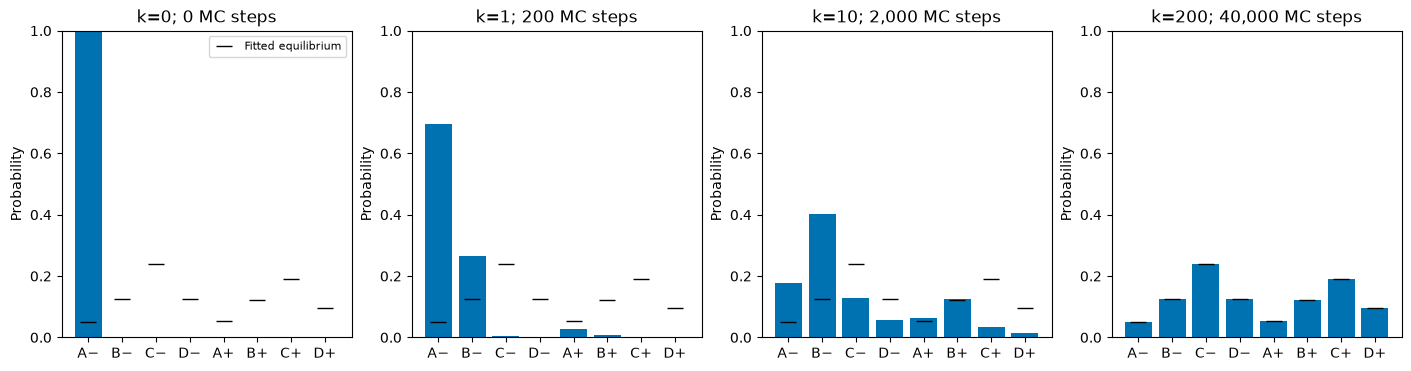

In [7]:
p0=np.zeros(8);p0[0]=1
a=p0@psi
N_LAGS=200
population=np.empty((N_LAGS+1,8));population[0]=p0
for k in range(N_LAGS):population[k+1]=population[k]@T
spectral=np.array([pi*(psi@(a*vals**k)) for k in range(N_LAGS+1)])
np.testing.assert_allclose(spectral,population,atol=1e-10)
np.testing.assert_allclose(population.sum(1),1,atol=1e-12)
assert population.min()>-1e-12
TV=.5*abs(population-pi).sum(1)
print("Mode | initial amplitude | eigenvalue")
for i in range(8):print(f"{i+1:4d} | {a[i]:17.5f} | {vals[i]:.6f}")
print("Final distance to fitted equilibrium:",TV[-1])
fig,axes=plt.subplots(1,4,figsize=(14,3.6),layout="constrained")
for ax,k in zip(axes,[0,1,10,200]):
    ax.bar(np.arange(8),population[k],color="#0072b2")
    ax.plot(np.arange(8),pi,"k_",ms=12,label="Fitted equilibrium")
    ax.set(xticks=range(8),xticklabels=labels,ylim=(0,1),title=f"k={k}; {k*LAG:,} MC steps",ylabel="Probability")
axes[0].legend(fontsize=8)
fig.savefig(OUTPUT/"Prinz_8well_relaxation.png",dpi=180);plt.show()


## 7. Two movies, two different meanings
**MC trajectory:** one particle moves on the energy surface; the running histogram includes every visit. It is a time average and will fluctuate.

**Ensemble relaxation:** all initial probability is in A−. The movie updates eight populations, their excess/depletion relative to fitted equilibrium, and all seven nonstationary amplitudes. This is deterministic propagation of the fitted MSM, not a noisy single-particle histogram. Fixed nonlinear color scales reveal small probabilities without rescaling each frame.

The movie cell exports portable MP4 files and embeds them in Colab. Set EXPORT_MOVIES=False to skip rendering during quick experiments.

In [8]:
EXPORT_MOVIES = False
print('Optional movie rendering skipped; numerical analyses and static plots are retained.')

Optional movie rendering skipped; numerical analyses and static plots are retained.



## Question 1. Equilibrium populations and free-energy surface


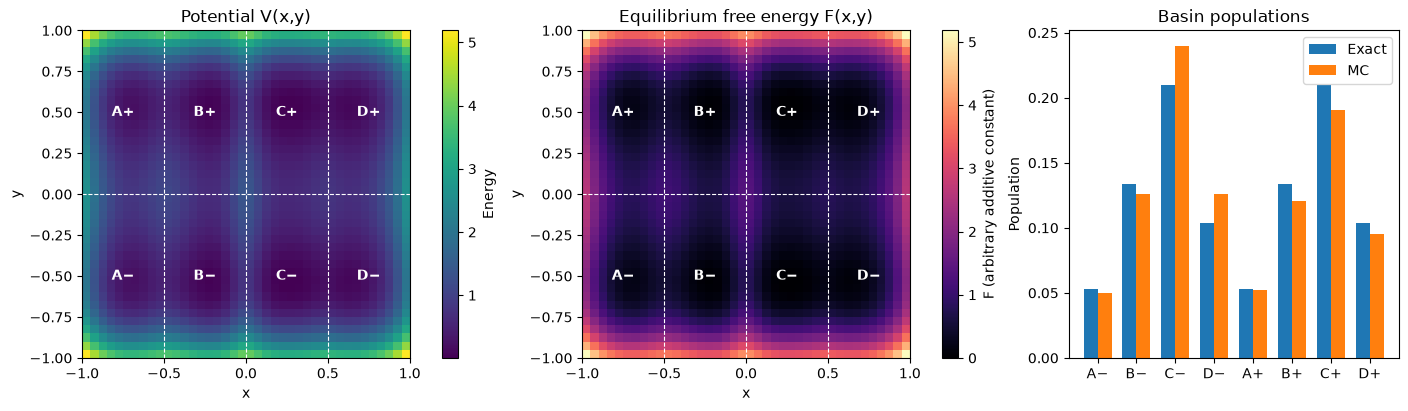

Exact basin populations: {'A−': np.float64(0.05273456742683782), 'B−': np.float64(0.13345766713865043), 'C−': np.float64(0.2097395137503389), 'D−': np.float64(0.10406825168417294), 'A+': np.float64(0.0527345674268378), 'B+': np.float64(0.13345766713865043), 'C+': np.float64(0.2097395137503389), 'D+': np.float64(0.10406825168417295)}
Empirical basin populations: {'A−': np.float64(0.04969730121079518), 'B−': np.float64(0.1261184955260179), 'C−': np.float64(0.23975454098183607), 'D−': np.float64(0.12576799692801224), 'A+': np.float64(0.05242479030083878), 'B+': np.float64(0.12060701757192972), 'C+': np.float64(0.1905652377390491), 'D+': np.float64(0.09506461974152103)}


In [9]:

# Exact equilibrium free energy and basin populations
free_energy = -(1.0/beta) * np.log(np.maximum(W, np.finfo(float).tiny))
free_energy -= free_energy.min()
pi_empirical = observed @ H

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
im = axes[0].imshow(energy, origin="lower", extent=(-1,1,-1,1), cmap="viridis")
basin_grid(axes[0]); axes[0].set(title="Potential V(x,y)", xlabel="x", ylabel="y")
fig.colorbar(im, ax=axes[0], label="Energy")
im = axes[1].imshow(free_energy, origin="lower", extent=(-1,1,-1,1), cmap="magma")
basin_grid(axes[1]); axes[1].set(title="Equilibrium free energy F(x,y)", xlabel="x", ylabel="y")
fig.colorbar(im, ax=axes[1], label="F (arbitrary additive constant)")
xx = np.arange(8)
axes[2].bar(xx-.18, pi_exact, width=.36, label="Exact")
axes[2].bar(xx+.18, pi_empirical, width=.36, label="MC")
axes[2].set(xticks=xx, xticklabels=labels, ylabel="Population", title="Basin populations")
axes[2].legend()
plt.show()
print("Exact basin populations:", dict(zip(labels, pi_exact)))
print("Empirical basin populations:", dict(zip(labels, pi_empirical)))



## Question 2. Discretization and state-partition justification

The continuous \((x,y)\) plane is divided into eight rectangular states: four intervals along
\(x\), separated by the three boundaries \(-0.5,0,0.5\), and two intervals along \(y\),
separated at \(y=0\). This partition places one basin in each state and preserves the
spatial organization of the eight minima. It is interpretable and gives a compact \(8\times8\)
model. Its limitation is that transitions within a rectangle are not resolved; therefore
the Markov approximation must be tested rather than assumed.



## Question 3. Reversible MSM at a lag of 100 MC steps

We symmetrize the transition counts and row-normalize to obtain
a reversible transition matrix. The stationary distribution is estimated from the
symmetrized count totals.

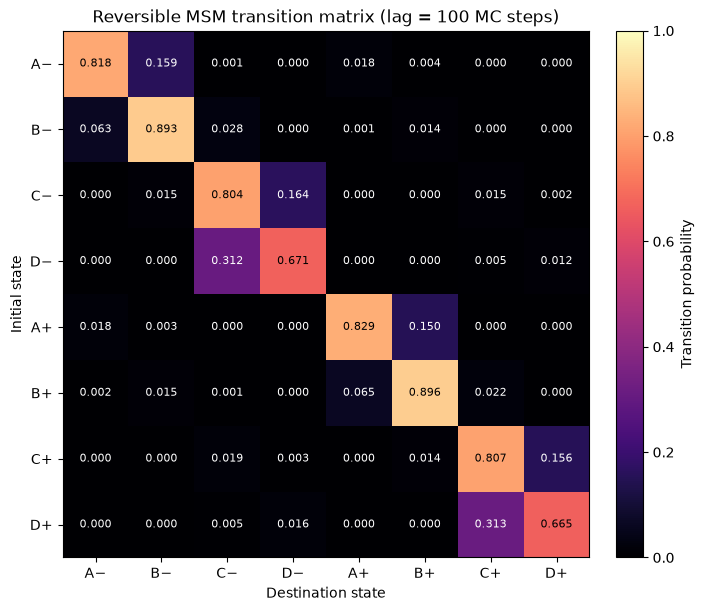

Estimated stationary distribution: {'A−': np.float64(0.049694929191960016), 'B−': np.float64(0.12609118210811482), 'C−': np.float64(0.23974769008527377), 'D−': np.float64(0.1257210355300699), 'A+': np.float64(0.052445768524335634), 'B+': np.float64(0.12065527949067831), 'C+': np.float64(0.19057421739008648), 'D+': np.float64(0.09506989767948107)}
Maximum detailed-balance residual: 3.469446951953614e-18


In [10]:

LAG100 = 100
C100 = counts_at(training, LAG100)
T100, pi100 = fit(C100)
np.testing.assert_allclose(T100.sum(axis=1), 1.0, atol=1e-12)
np.testing.assert_allclose(pi100 @ T100, pi100, atol=1e-12)
np.testing.assert_allclose(pi100[:,None]*T100, pi100[None,:]*T100.T, atol=1e-12)

fig, ax = plt.subplots(figsize=(7,6), layout="constrained")
im = ax.imshow(T100, vmin=0, vmax=1, cmap="magma")
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{T100[i,j]:.3f}", ha="center", va="center",
                fontsize=8, color="black" if T100[i,j] > .6 else "white")
ax.set(xticks=range(8), yticks=range(8), xticklabels=labels, yticklabels=labels,
       xlabel="Destination state", ylabel="Initial state",
       title="Reversible MSM transition matrix (lag = 100 MC steps)")
fig.colorbar(im, ax=ax, label="Transition probability")
plt.show()
print("Estimated stationary distribution:", dict(zip(labels, pi100)))
print("Maximum detailed-balance residual:",
      np.max(np.abs(pi100[:,None]*T100-pi100[None,:]*T100.T)))



## Question 4. Dominant nonstationary eigenvectors

The reversible matrix is diagonalized in its symmetric representation. The leading
eigenvector is the stationary mode, the remaining eigenvectors describe
independent patterns of population exchange among the eight basins.


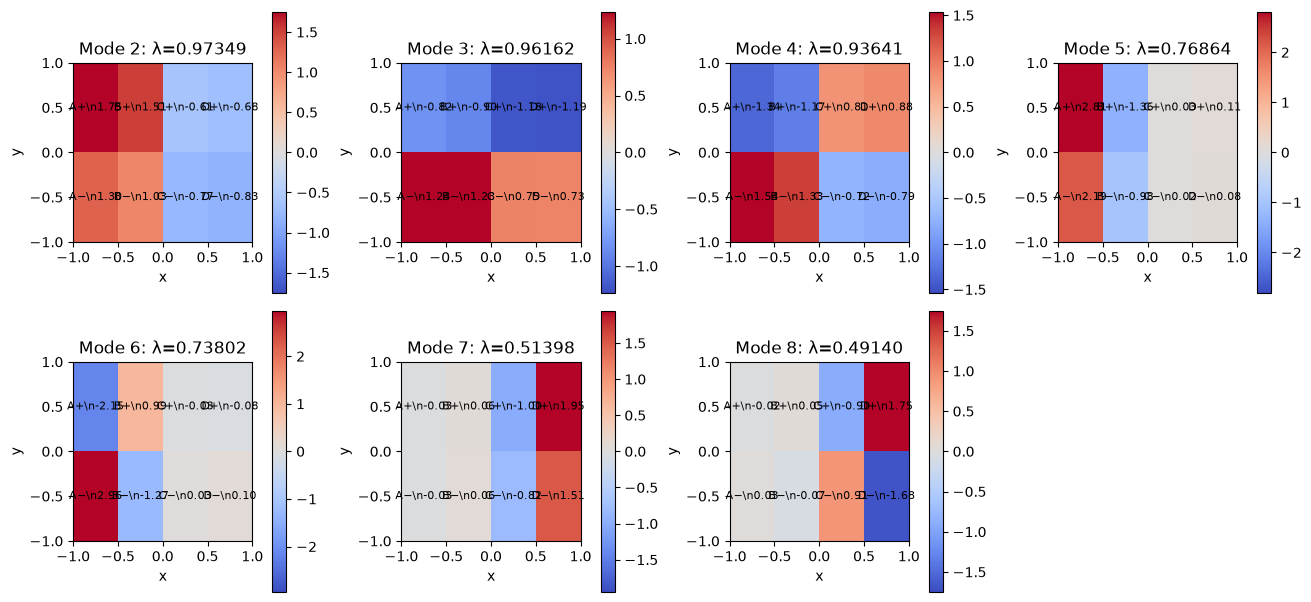

Nonstationary eigenvalues: [0.9735 0.9616 0.9364 0.7686 0.738  0.514  0.4914]
Implied relaxation times (MC steps): [3722.21   2554.9435 1521.9903  380.0406  329.1835  150.249   140.7466]


In [11]:

eval100, evec100 = eigensystem(T100, pi100)
fig, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
for mode, ax in enumerate(axes.ravel(), start=1):
    if mode >= 8:
        ax.axis("off")
        continue
    field = evec100[:,mode].reshape(2,4)
    vmax = np.max(np.abs(field))
    im = ax.imshow(field, origin="lower", extent=(-1,1,-1,1),
                   cmap="coolwarm", vmin=-vmax, vmax=vmax)
    for s in range(8):
        ax.text(centers_x[s%4], centers_y[s//4],
                f"{labels[s]}\\n{evec100[s,mode]:.2f}",
                ha="center", va="center", fontsize=8)
    ax.set(title=f"Mode {mode+1}: λ={eval100[mode]:.5f}",
           xlabel="x", ylabel="y")
    fig.colorbar(im, ax=ax)
plt.show()
times100 = np.array([-LAG100/np.log(z) if 0 < z < 1 else np.nan
                     for z in eval100[1:]])
print("Nonstationary eigenvalues:", eval100[1:])
print("Implied relaxation times (MC steps):", times100)


## Question 5. CK agreement at 100 and 10 MC steps; return and interstate transitions

For each lag, the Chapman–Kolmogorov prediction is \(T(\tau)^k\).

Uncertainty is assessed by resampling whole independent trajectories (rather than
individual, strongly correlated time points). This captures between-trajectory sampling
variation, although four validation trajectories make the interval estimates themselves
somewhat noisy.


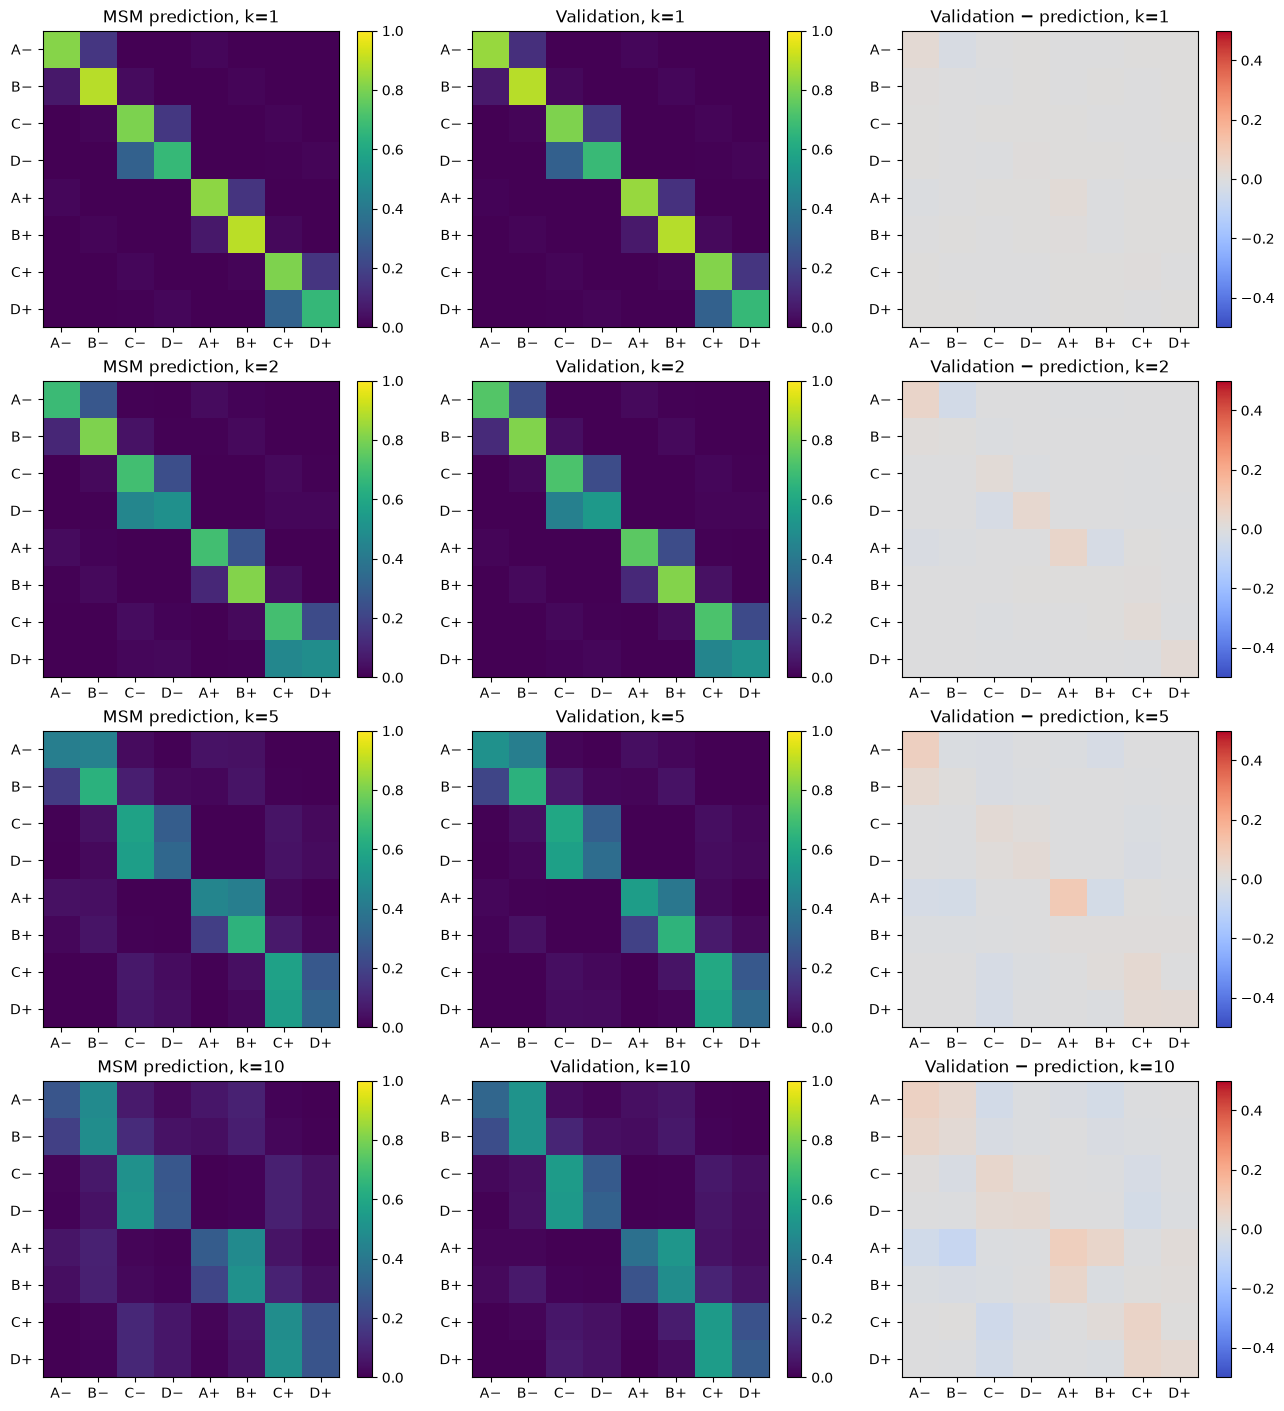

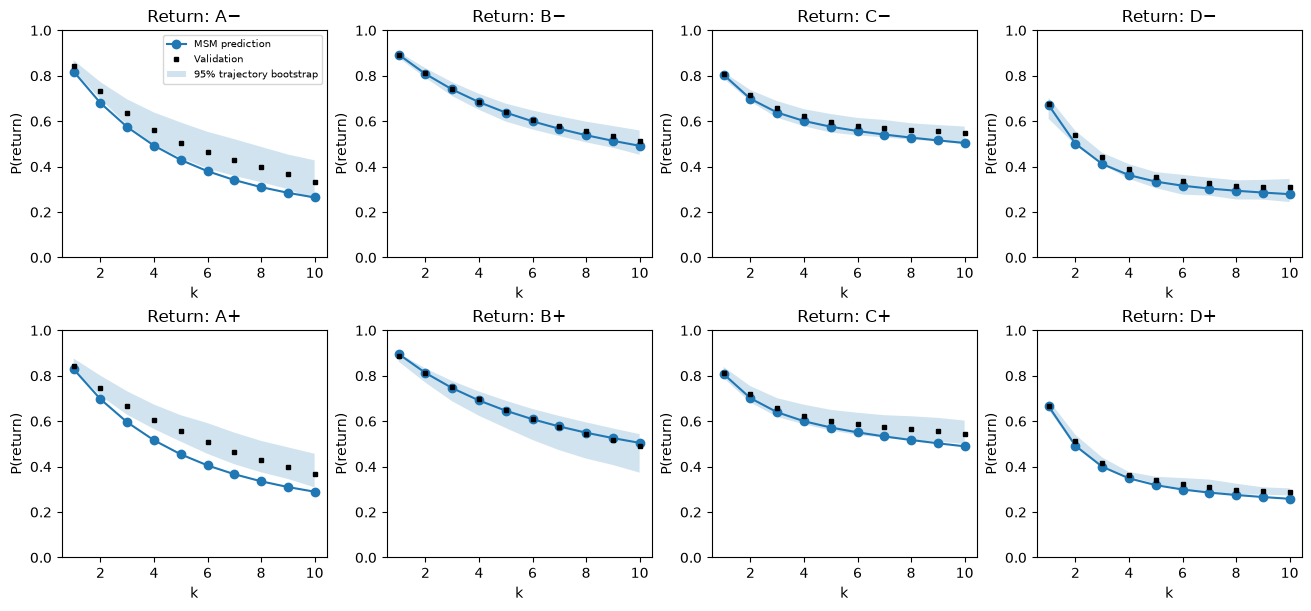

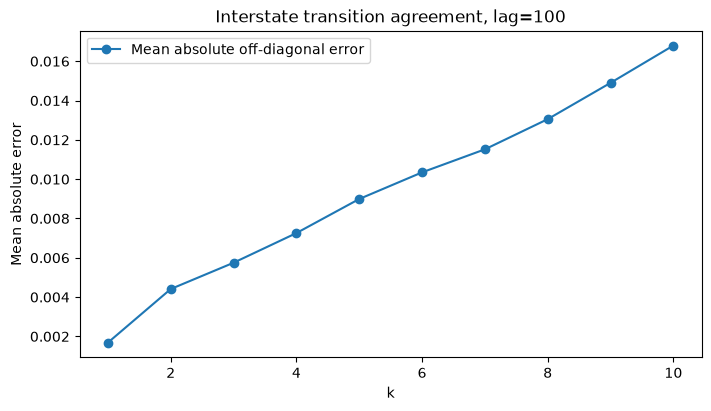

--- CK summary, base lag 100 ---
k= 1, t= 100: mean abs error=0.00255; max abs error=0.02639; off-diagonal mean abs error=0.00168
k= 2, t= 200: mean abs error=0.00697; max abs error=0.05289; off-diagonal mean abs error=0.00441
k= 5, t= 500: mean abs error=0.01226; max abs error=0.10116; off-diagonal mean abs error=0.00899
k=10, t=1000: mean abs error=0.01999; max abs error=0.07835; off-diagonal mean abs error=0.01680


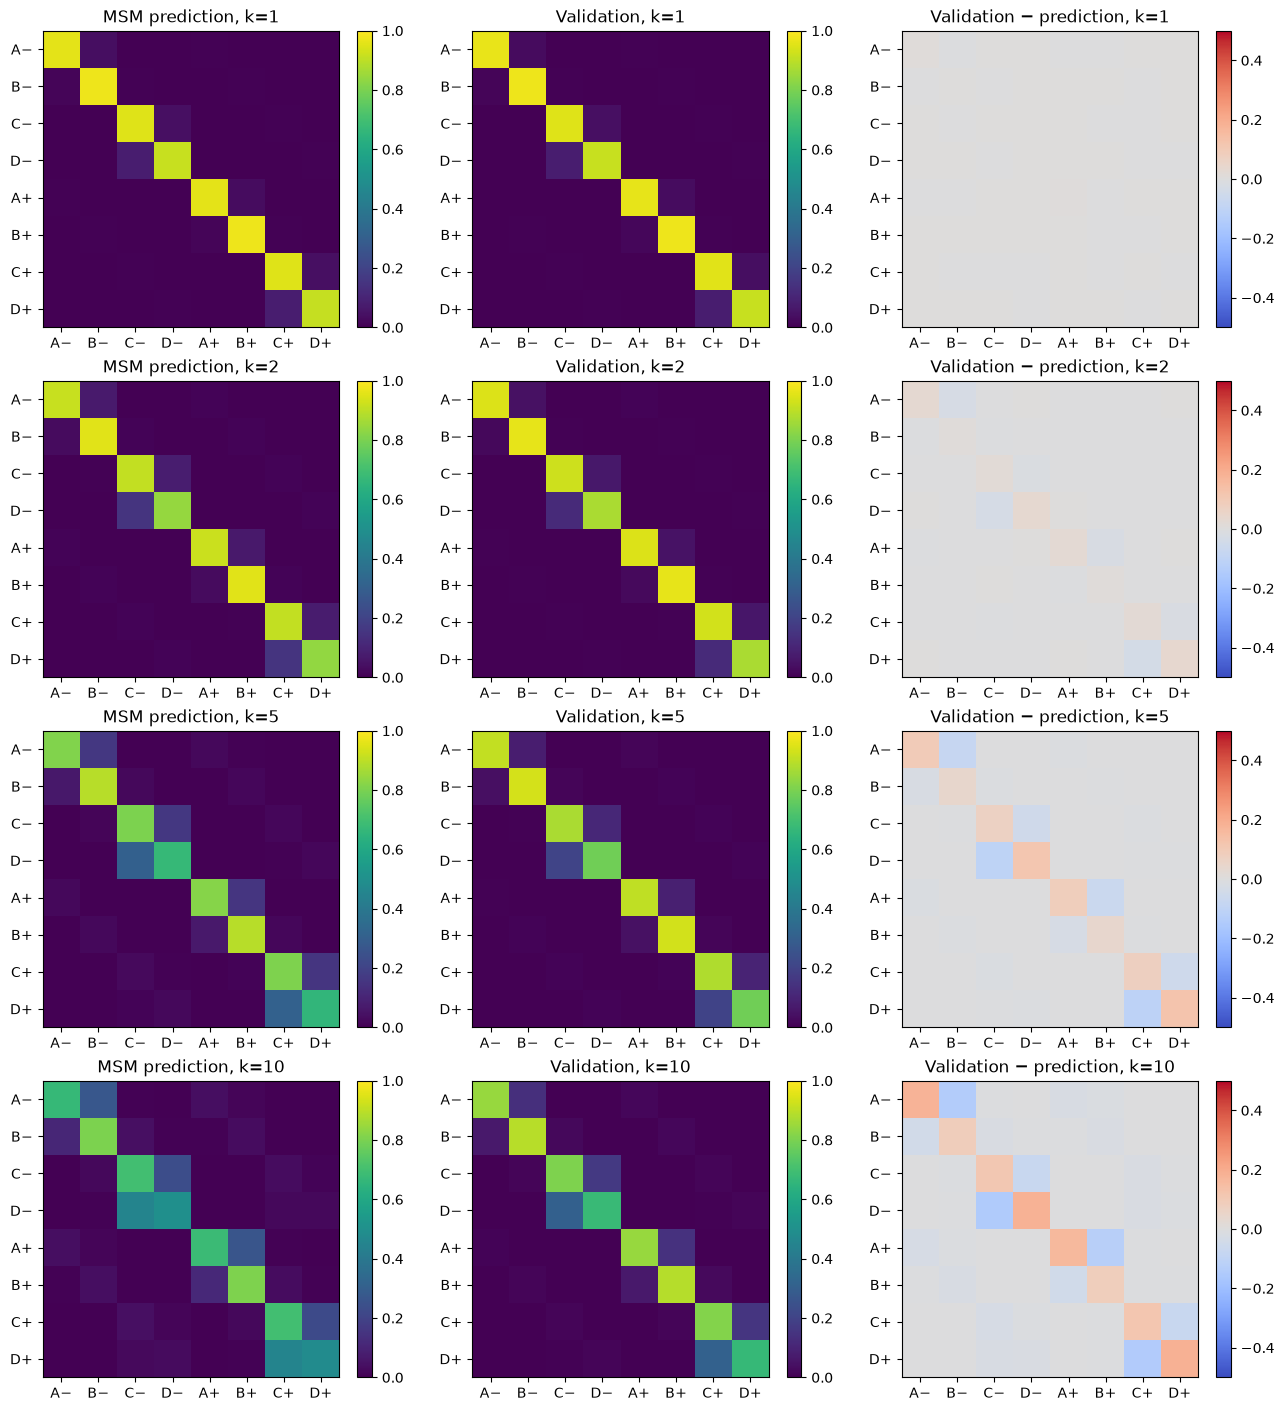

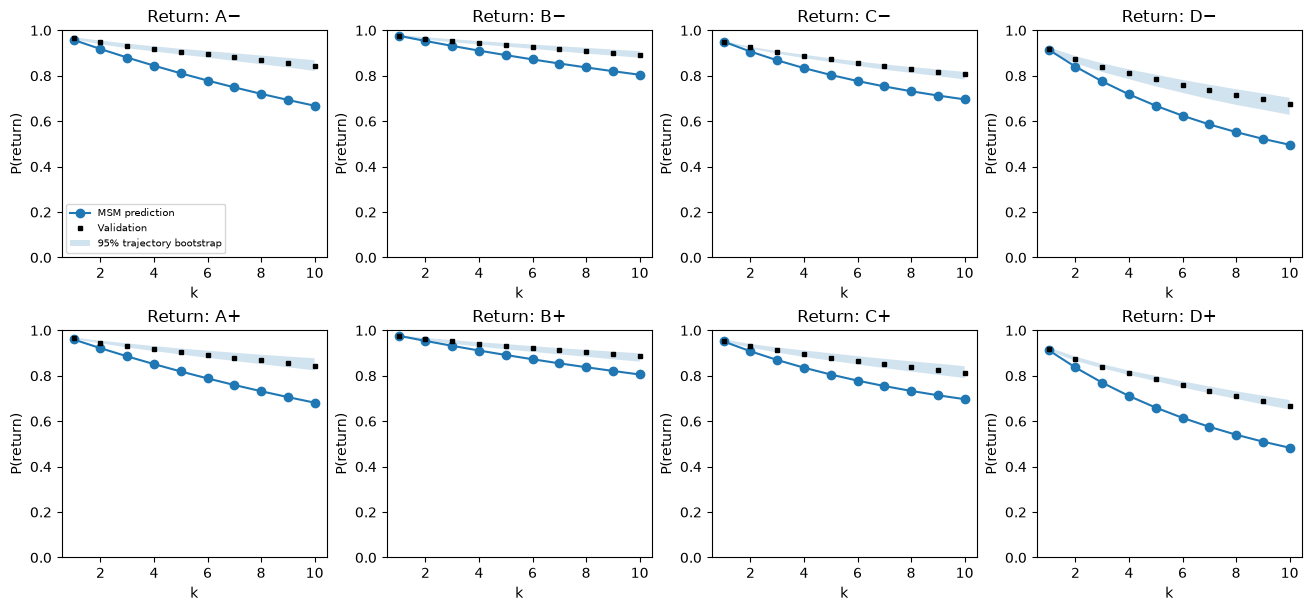

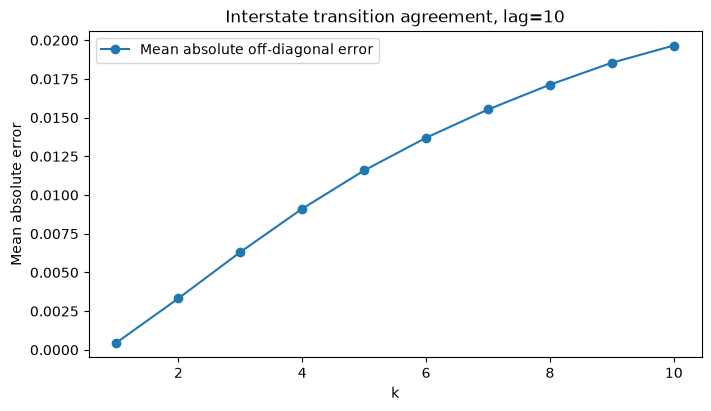

--- CK summary, base lag 10 ---
k= 1, t=  10: mean abs error=0.00074; max abs error=0.00789; off-diagonal mean abs error=0.00046
k= 2, t=  20: mean abs error=0.00581; max abs error=0.03698; off-diagonal mean abs error=0.00332
k= 5, t=  50: mean abs error=0.02028; max abs error=0.12493; off-diagonal mean abs error=0.01159
k=10, t= 100: mean abs error=0.03440; max abs error=0.18571; off-diagonal mean abs error=0.01966


In [12]:

def direct_transition(paths, lag):
    counts = counts_at(paths, lag)
    row = counts.sum(axis=1)
    out = np.full((8,8), np.nan, dtype=float)
    good = row > 0
    out[good] = counts[good] / row[good,None]
    return out

def ck_analysis(lag, n_boot=300, seed=1234):
    C = counts_at(training, lag)
    Tlag, pilag = fit(C)
    ks = np.arange(1, 11)
    pred = np.array([np.linalg.matrix_power(Tlag, int(k)) for k in ks])
    direct = np.array([direct_transition(validation, int(k*lag)) for k in ks])

    # Bootstrap independent trajectory units for uncertainty in direct CK estimates.
    rng = np.random.default_rng(seed)
    boot = np.full((n_boot, len(ks), 8, 8), np.nan)
    for b in range(n_boot):
        chosen = rng.integers(0, len(validation), size=len(validation))
        sample = [validation[j] for j in chosen]
        for qidx, k in enumerate(ks):
            boot[b,qidx] = direct_transition(sample, int(k*lag))
    lo = np.nanquantile(boot, .025, axis=0)
    hi = np.nanquantile(boot, .975, axis=0)
    return Tlag, pilag, ks, pred, direct, lo, hi

ck100 = ck_analysis(100, seed=1001)
ck10 = ck_analysis(10, seed=1002)

def plot_ck(ck, lag):
    Tlag, pilag, ks, pred, direct, lo, hi = ck
    selected = [0,1,4,9]  
    fig, axes = plt.subplots(4, 3, figsize=(13, 14), layout="constrained")
    for row, qidx in enumerate(selected):

        for col, (mat, title) in enumerate([
            (pred[qidx], f"MSM prediction, k={ks[qidx]}"),
            (direct[qidx], f"Validation, k={ks[qidx]}"),
            (direct[qidx]-pred[qidx], f"Validation − prediction, k={ks[qidx]}")
        ]):
            im = axes[row,col].imshow(mat, cmap="coolwarm" if col==2 else "viridis",
                                      vmin=-.5 if col==2 else 0,
                                      vmax=.5 if col==2 else 1)
            axes[row,col].set(title=title, xticks=range(8), yticks=range(8),
                              xticklabels=labels, yticklabels=labels)
            fig.colorbar(im, ax=axes[row,col], fraction=.046)
    plt.show()

    fig, axes = plt.subplots(2,4,figsize=(13,6),layout="constrained")
    for s, ax in enumerate(axes.ravel()):
        ax.plot(ks, pred[:,s,s], "o-", label="MSM prediction")
        ax.plot(ks, direct[:,s,s], "ks", ms=3, label="Validation")
        ax.fill_between(ks, lo[:,s,s], hi[:,s,s], alpha=.2, label="95% trajectory bootstrap")
        ax.set(title=f"Return: {labels[s]}", xlabel="k", ylabel="P(return)", ylim=(0,1))
    axes[0,0].legend(fontsize=7)
    plt.show()


    offdiag = ~np.eye(8, dtype=bool)
    abs_error = np.abs(direct-pred)
    mean_offdiag = np.nanmean(abs_error[:,offdiag], axis=1)
    fig, ax = plt.subplots(figsize=(7,4), layout="constrained")
    ax.plot(ks, mean_offdiag, "o-", label="Mean absolute off-diagonal error")
    ax.set(xlabel="k", ylabel="Mean absolute error",
           title=f"Interstate transition agreement, lag={lag}")
    ax.legend()
    plt.show()

    print(f"--- CK summary, base lag {lag} ---")
    for qidx in [0,1,4,9]:
        valid = np.isfinite(direct[qidx])
        err = np.abs(direct[qidx]-pred[qidx])
        print(f"k={ks[qidx]:2d}, t={ks[qidx]*lag:4d}: "
              f"mean abs error={np.nanmean(err):.5f}; "
              f"max abs error={np.nanmax(err):.5f}; "
              f"off-diagonal mean abs error={np.nanmean(err[offdiag]):.5f}")
    return

plot_ck(ck100, 100)
plot_ck(ck10, 10)



## Question 6. Propagate a population initially localized in one state


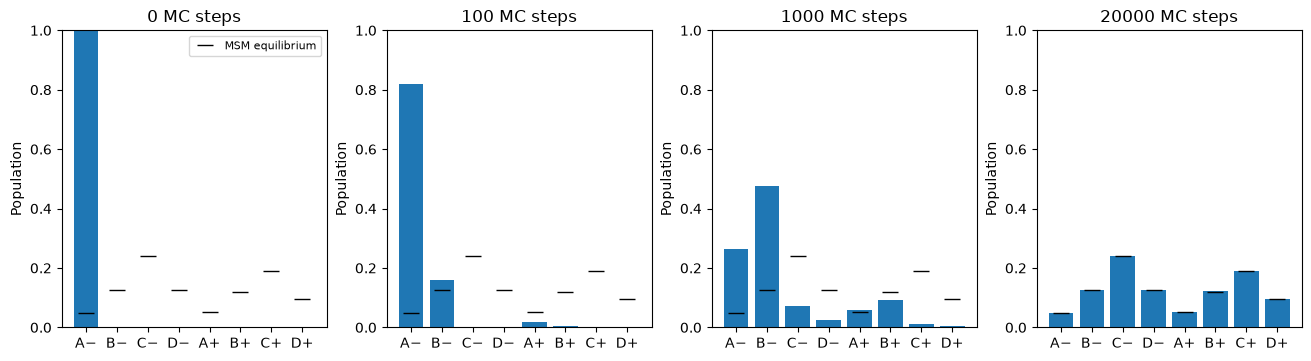

Final total-variation distance to equilibrium: 0.002864967523786493


In [13]:

p0_100 = np.zeros(8); p0_100[0] = 1.0
nsteps_relax = 200
pop100 = np.empty((nsteps_relax+1,8)); pop100[0] = p0_100
for k in range(nsteps_relax):
    pop100[k+1] = pop100[k] @ T100
assert np.allclose(pop100.sum(axis=1), 1.0)
fig, axes = plt.subplots(1,4,figsize=(13,3.5),layout="constrained")
for ax, k in zip(axes, [0,1,10,200]):
    ax.bar(range(8),pop100[k])
    ax.plot(range(8),pi100,"k_",ms=12,label="MSM equilibrium")
    ax.set(xticks=range(8),xticklabels=labels,ylim=(0,1),
           title=f"{k*LAG100} MC steps",ylabel="Population")
axes[0].legend(fontsize=8)
plt.show()
print("Final total-variation distance to equilibrium:",
      .5*np.abs(pop100[-1]-pi100).sum())



## Question 7. Initial mode amplitudes and modal contributions


Mode | initial amplitude | eigenvalue | implied time (MC steps)
   1 |         1.000000 |  1.000000 |          nan
   2 |         1.300011 |  0.973492 |     3722.210
   3 |         1.237180 |  0.961616 |     2554.944
   4 |         1.538623 |  0.936409 |     1521.990
   5 |         2.189525 |  0.768642 |      380.041
   6 |         2.956145 |  0.738022 |      329.183
   7 |        -0.030364 |  0.513985 |      150.249
   8 |         0.032175 |  0.491400 |      140.747


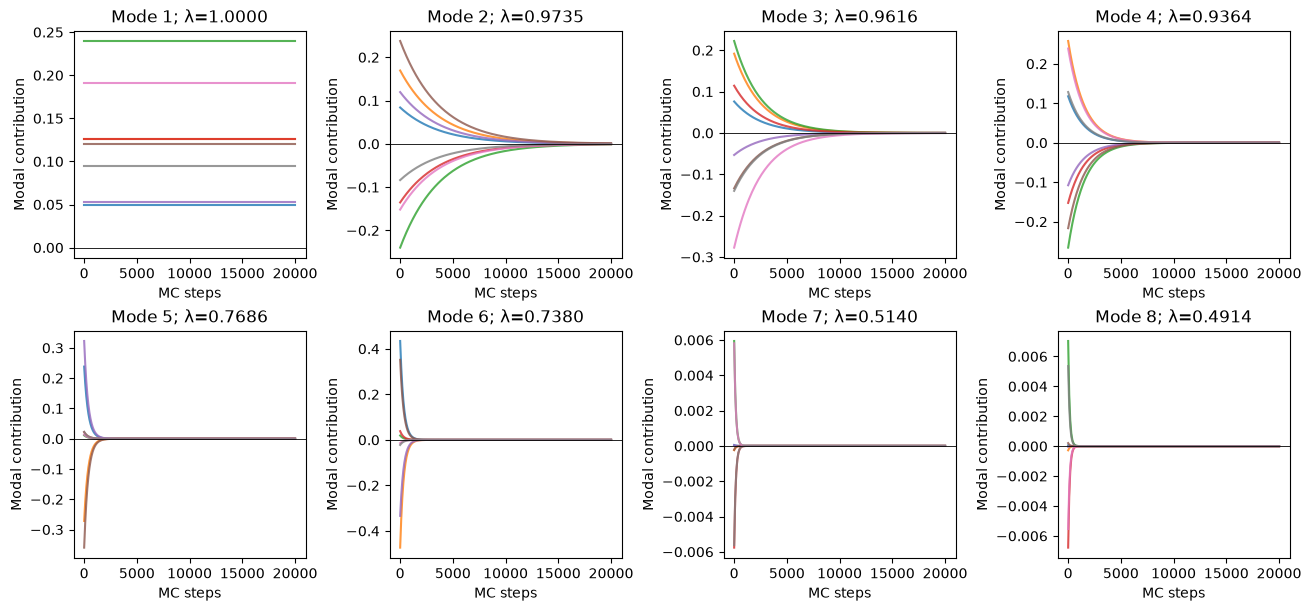

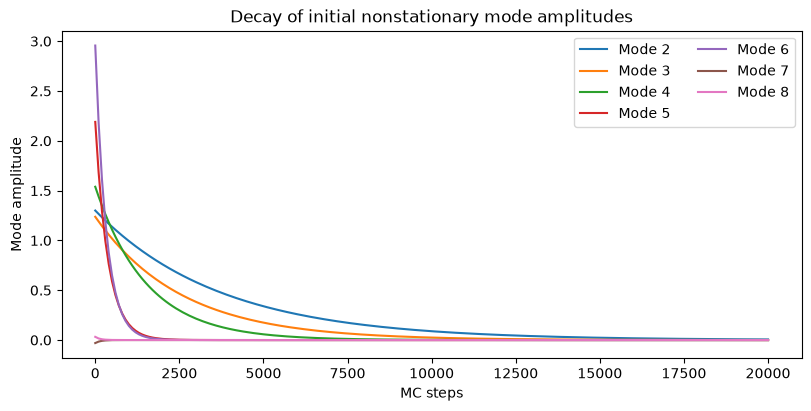

In [ ]:

amp100 = p0_100 @ evec100
modal_contrib = np.empty((nsteps_relax+1,8,8))
for k in range(nsteps_relax+1):
    modal_contrib[k] = pi100[:,None] * (
        evec100 * (amp100 * eval100**k)[None,:]
    )

reconstructed = modal_contrib.sum(axis=2)
np.testing.assert_allclose(reconstructed, pop100, atol=1e-10)
print("Mode | initial amplitude | eigenvalue | implied time (MC steps)")
for i in range(8):
    ti = np.nan if i==0 else (-LAG100/np.log(eval100[i]) if 0<eval100[i]<1 else np.nan)
    print(f"{i+1:4d} | {amp100[i]:16.6f} | {eval100[i]:9.6f} | {ti:12.3f}")

fig, axes = plt.subplots(2,4,figsize=(13,6),layout="constrained")
for i, ax in enumerate(axes.ravel()):

    ax.plot(np.arange(nsteps_relax+1)*LAG100,
            modal_contrib[:,:,i], alpha=.8)
    ax.axhline(0,color="black",lw=.6)
    ax.set(title=f"Mode {i+1}; λ={eval100[i]:.4f}",
           xlabel="MC steps", ylabel="Modal contribution")
plt.show()

fig, ax = plt.subplots(figsize=(8,4),layout="constrained")
for i in range(1,8):
    ax.plot(np.arange(nsteps_relax+1)*LAG100,
            amp100[i]*eval100[i]**np.arange(nsteps_relax+1),
            label=f"Mode {i+1}")
ax.set(xlabel="MC steps",ylabel="Mode amplitude",
       title="Decay of initial nonstationary mode amplitudes")
ax.legend(ncol=2)
plt.show()



## Question 8. Eigenmode autocorrelation functions and implied relaxation times


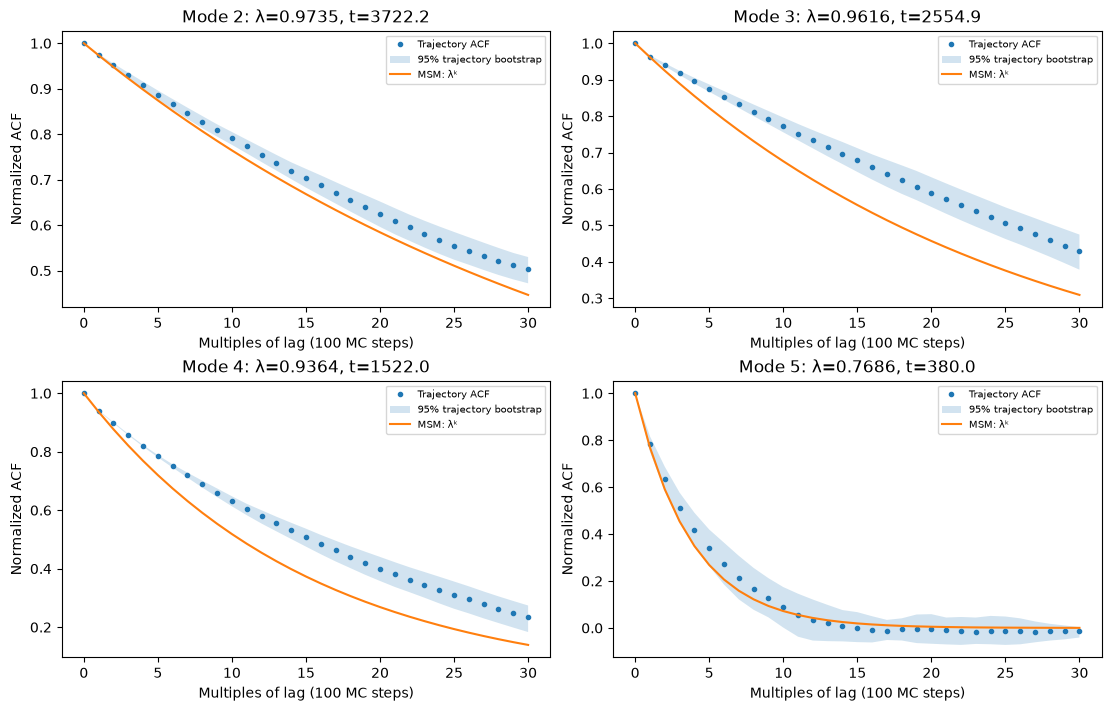

Lag 100: eigenvalues: [0.9735 0.9616 0.9364 0.7686]
Lag 100: implied relaxation times (MC steps): [3722.21   2554.9435 1521.9903  380.0406]


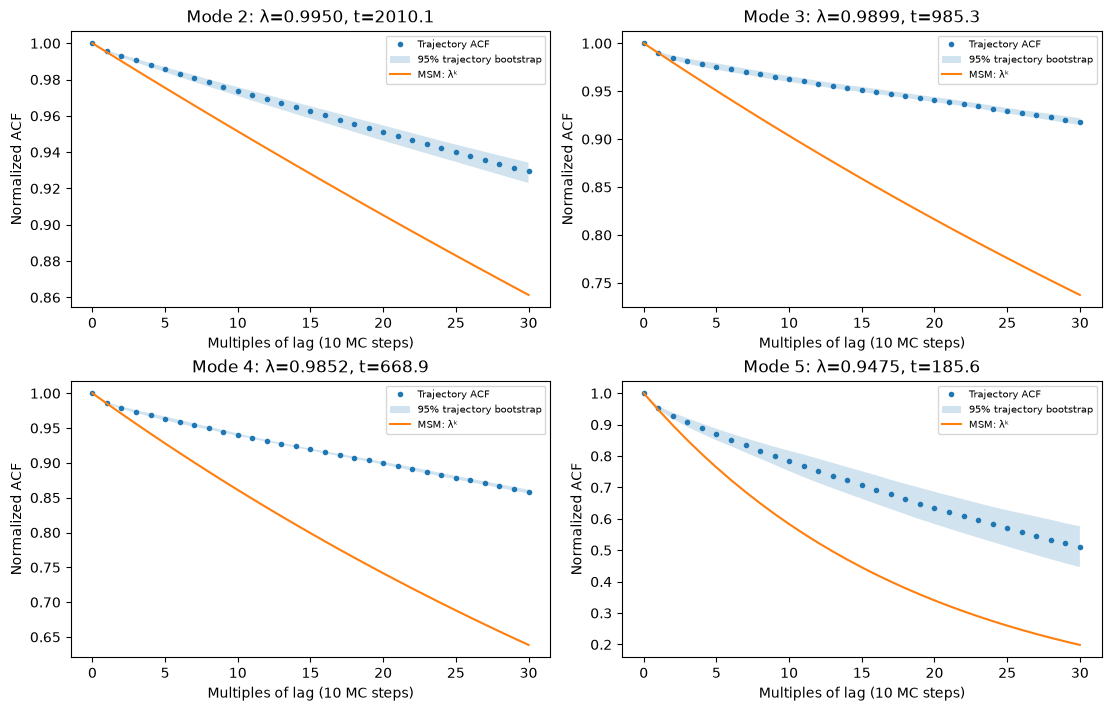

Lag 10: eigenvalues: [0.995  0.9899 0.9852 0.9475]
Lag 10: implied relaxation times (MC steps): [2010.137   985.2647  668.8793  185.5665]


In [16]:

def autocorr_at_lags(path, psi_mode, lag, max_k=30):
    states = assignment[path]
    z = psi_mode[states].astype(float)
    z = z - z.mean()
    denom = np.dot(z,z)
    if denom <= 0:
        return np.full(max_k+1, np.nan)
    return np.array([np.dot(z[:len(z)-k*lag], z[k*lag:]) / denom
                     if k*lag < len(z) else np.nan
                     for k in range(max_k+1)])

def mode_acf_analysis(Tlag, pilag, lag, trajectories, max_modes=4,
                      max_k=30, n_boot=300, seed=99):
    eigvals, eigvecs = eigensystem(Tlag, pilag)
    rng = np.random.default_rng(seed)
    all_acf = np.array([
        [autocorr_at_lags(path, eigvecs[:,m], lag, max_k)
         for path in trajectories]
        for m in range(1, max_modes+1)
    ])
    mean_acf = np.nanmean(all_acf, axis=1)
    boots = np.empty((n_boot,max_modes,max_k+1))
    for b in range(n_boot):
        ids = rng.integers(0,len(trajectories),size=len(trajectories))
        boots[b] = np.nanmean(all_acf[:,ids,:],axis=1)
    lower, upper = np.nanquantile(boots,[.025,.975],axis=0)
    times = np.array([-lag/np.log(v) if 0<v<1 else np.nan
                      for v in eigvals[1:max_modes+1]])
    steps = np.arange(max_k+1)
    fig, axes = plt.subplots(2,2,figsize=(11,7),layout="constrained")
    for m,ax in enumerate(axes.ravel()):
        ax.plot(steps, mean_acf[m], "o", ms=3, label="Trajectory ACF")
        ax.fill_between(steps,lower[m],upper[m],alpha=.2,label="95% trajectory bootstrap")
        ax.plot(steps,eigvals[m+1]**steps,"-",label="MSM: λᵏ")
        ax.set(title=f"Mode {m+2}: λ={eigvals[m+1]:.4f}, t={times[m]:.1f}",
               xlabel=f"Multiples of lag ({lag} MC steps)",ylabel="Normalized ACF")
        ax.legend(fontsize=7)
    plt.show()
    print(f"Lag {lag}: eigenvalues:", eigvals[1:max_modes+1])
    print(f"Lag {lag}: implied relaxation times (MC steps):", times)
    return eigvals,eigvecs,mean_acf,lower,upper,times

acf100 = mode_acf_analysis(T100, pi100, 100, validation, seed=3100)
T10, pi10 = fit(counts_at(training,10))
acf10 = mode_acf_analysis(T10, pi10, 10, validation, seed=3101)


The equilibrium surface and basin populations are determined directly from the supplied
potential and Boltzmann weights; the MSM estimates are instead learned from finite MC
trajectories. The eight rectangular states are a transparent coarse partition, but their
Markovianity is lag-dependent. The 10-step and 100-step CK plots should be judged using
both diagonal return probabilities and off-diagonal interstate transitions, with the
trajectory-bootstrap intervals providing a measure of sampling uncertainty.

A longer lag can improve effective Markovianity while reducing the number of observed
transitions and increasing statistical uncertainty. The eigenvectors, amplitudes,
relaxation curves, and autocorrelation predictions are all properties of the fitted
coarse-grained model. They should not be interpreted as exact dynamics at arbitrarily
short times or as physical time scales without an independent calibration of MC steps.
